# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и искусственный интеллект
**Модуль 4:** Инженерия признаков и работа с нестандартными данными
**Датасет:** Online Shoppers Purchasing Intention

**Выполнил:** Галямеев Михаил Русланович
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/GMR005/ml-course-galyameev
**Путь к модулю:** `module-4-features/notebook.ipynb`
**Дата сдачи:** 2026-11-02

## Введение

**Какую задачу решаем?** Мы решаем задачу бинарной классификации: по характеристикам одной сессии пользователя на сайте интернет-магазина предсказать, завершится ли эта сессия покупкой (`Revenue = 1`) или нет (`Revenue = 0`). Каждая строка датасета — это отдельная сессия, описанная количеством и длительностью просмотра страниц, показателями отказов и выходов, ценностью страниц, месяцем, типом посетителя и техническими признаками.

**Что такое инженерия признаков?** Инженерия признаков — это процесс создания новых информативных переменных из уже имеющихся данных, а также преобразования признаков к виду, удобному для модели. Хорошо сконструированные признаки позволяют даже простым моделям улавливать закономерности, которые сложно заметить в исходных столбцах. В этой работе мы агрегируем поведение пользователя (суммы страниц и времени), строим отношения показателей и извлекаем временные характеристики.

**Почему для IT-компании важно прогнозировать покупку?** Интернет-магазину важно понимать, какие сессии близки к покупке, чтобы вовремя предложить помощь, промокод или упростить оформление заказа. Прогноз также помогает оптимизировать маркетинговый бюджет: вместо одинаковых скидок всем пользователям компания может таргетировать коммуникации на сессии с высокой вероятностью конверсии. Кроме того, анализ важности признаков показывает, какие элементы сайта и какие источники трафика действительно влияют на продажи.

**Какая метрика важнее в этой задаче?** Из-за сильного дисбаланса классов (примерно 84.5% против 15.5%) Accuracy может вводить в заблуждение: модель, всегда предсказывающая «нет покупки», уже имеет точность около 84.5%, но бесполезна для бизнеса. Поэтому основной метрикой выберем **ROC-AUC**, которая оценивает качество ранжирования вероятностей независимо от порога. Дополнительно будем контролировать **F1**, **Recall** и **Precision**: в зависимости от стоимости пропущенной покупки и ложного срабатывания бизнес может выбрать подходящий порог.

**Цель работы:**
1. Создать 5+ новых признаков на основе поведения пользователя (суммы, средние, отношения, временные и бинарные признаки).
2. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по метрикам и времени обучения.
3. Интерпретировать лучшую модель через SHAP и сформулировать бизнес-инсайты для e-commerce.

## Теоретическая часть

### Feature Engineering

Feature Engineering — это этап подготовки данных, на котором аналитик создаёт новые признаки и преобразует существующие так, чтобы модель могла лучше выделить закономерности. В табличных задачах именно признаки часто определяют качество модели сильнее, чем выбор алгоритма. В IT-компаниях Feature Engineering применяется для построения скоринговых моделей, прогнозирования оттока, оценки конверсии и рекомендаций. Например, вместо двух отдельных столбцов «время на товарных страницах» и «число товарных страниц» полезно получить среднее время просмотра одной страницы. Такой признак компактнее описывает вовлечённость пользователя и может быть устойчивее к масштабу сессии.

### Категориальные признаки

Категориальные признаки принимают значения из конечного набора, но не имеют естественного порядка. **Label Encoding** заменяет каждую категорию целым числом; это компактно, но может ошибочно навязать модели порядок между категориями. **One-Hot Encoding** создаёт отдельный бинарный столбец для каждой категории и не вводит ложного порядка, однако увеличивает размерность. Для `VisitorType` и `Month` мы используем One-Hot Encoding, так как категорий немного и порядок между ними не является числовым. Для технических идентификаторов (`Browser`, `Region`, `TrafficType`) в этой работе оставляем числовые коды: древовидные модели способны разбивать их по порогам, хотя такой подход не идеален.

### Временные признаки

Временной признак `Month` изначально хранится строкой, поэтому модель не может использовать его как число. Мы строим `MonthNum` — номер месяца от 1 до 12, что позволяет учитывать сезонность: перед праздниками или в периоды распродаж поведение покупателей меняется. Дополнительно признак `IsWeekend` отделяет выходные от будних дней: в выходные пользователи могут дольше выбирать товары и чаще оформлять заказ. В более сложных задачах к временным признакам добавляют день недели, час суток, праздники и скользящие агрегаты по времени.

### Создание признаков на основе поведения

Поведенческие агрегаты суммируют действия пользователя за сессию. Мы строим общее число просмотренных страниц и общую длительность сессии:

$$TotalPages = Administrative + Informational + ProductRelated$$

$$TotalDuration = Administrative\_Duration + Informational\_Duration + ProductRelated\_Duration$$

Средняя ценность страницы и отношение показателей отказов к выходам помогают описать вовлечённость:

$$AvgPageValue = \frac{PageValues}{TotalPages + 1}, \qquad BounceExitRatio = \frac{BounceRates}{ExitRates + 0.001}$$

Единица и малое слагаемое в знаменателях защищают от деления на ноль. Такие отношения часто информативнее исходных величин, потому что нормируют поведение на размер сессии.

### Дисбаланс классов

Дисбаланс возникает, когда один класс встречается значительно реже другого. В нашем случае покупок около 15.5%, поэтому модель может «выучить» предсказывать преимущественно отрицательный класс. Для борьбы с этим используют взвешивание классов (`class_weight='balanced'`, `scale_pos_weight`, `auto_class_weights`), ресемплинг (SMOTE, undersampling), подбор порога классификации и метрики, устойчивые к дисбалансу (ROC-AUC, F1, Recall). В этой работе мы применяем взвешивание классов во всех четырёх моделях.

### SHAP

SHAP (SHapley Additive exPlanations) объясняет предсказание модели через значения Шепли из теории кооперативных игр. Каждый признак получает вклад в предсказание относительно базового значения; вклады складываются в отклонение прогноза от среднего. **Summary plot** показывает глобальную важность и направление влияния признаков, **bar plot** — среднюю абсолютную важность, **waterfall plot** объясняет одно конкретное предсказание, а **dependence plot** показывает зависимость вклада признака от его значения. SHAP ценен тем, что объяснения локальны и сопоставимы между объектами, что упрощает диалог аналитика с бизнесом.

### Bagging и Boosting

**Bagging** обучает много независимых моделей на бутстрэп-выборках и усредняет их:

$$H(x) = \frac{1}{M}\sum_{i=1}^{M} h_i(x)$$

**Boosting** строит модели последовательно, каждая следующая исправляет ошибки предыдущих:

$$F_m(x) = F_{m-1}(x) + \nu \, h_m(x)$$

где $\nu$ — темп обучения, а $h_m$ — очередная слабая модель. Bagging снижает дисперсию, boosting — смещение.

### Сравнение моделей

| Модель | Тип | Сильные стороны | Ограничения |
|--------|-----|-----------------|-------------|
| Random Forest | Bagging | Устойчивость к переобучению, работает «из коробки», не требует масштабирования | Медленнее на больших данных, менее точная на сложных зависимостях |
| XGBoost | Boosting | Высокая точность, регуляризация, гибкая настройка | Чувствителен к гиперпараметрам, требует аккуратной валидации |
| LightGBM | Boosting | Быстрое обучение, leaf-wise рост деревьев, эффективен на средних и больших данных | Может переобучаться на маленьких выборках |
| CatBoost | Boosting | Хорошо работает с категориальными признаками, устойчив к переобучению | Более медленное обучение, больший размер модели |

**Визуальное сравнение:** Random Forest — «параллельный» ансамбль независимых деревьев; XGBoost, LightGBM и CatBoost — «последовательные» ансамбли, где каждое новое дерево уточняет предыдущий прогноз.

## Описание данных

**Источник:** [UCI Machine Learning Repository, ID 468](https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset) (зеркало Kaggle: [Online Shoppers Intention](https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention)).

**Структура:**
- Всего примеров: 12 330 (по одной строке на сессию пользователя).
- Исходных признаков: 17 (+ целевая `Revenue`).
- Числовых признаков: 10.
- Категориальных/логических признаков: 7 (включая `Month`, `VisitorType`, `Weekend`).
- Пропусков в исходном датасете нет.

**Распределение классов:**
- `False` (нет покупки): 10 422 сессии (84.5%).
- `True` (покупка): 1 908 сессий (15.5%).

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Administrative | int | Число посещённых административных страниц | 0% |
| Administrative_Duration | float | Время на административных страницах, сек | 0% |
| Informational | int | Число информационных страниц | 0% |
| Informational_Duration | float | Время на информационных страницах, сек | 0% |
| ProductRelated | int | Число страниц с товарами | 0% |
| ProductRelated_Duration | float | Время на страницах с товарами, сек | 0% |
| BounceRates | float | Показатель отказов | 0% |
| ExitRates | float | Показатель выходов | 0% |
| PageValues | float | Средняя ценность просмотренной страницы | 0% |
| SpecialDay | float | Близость сессии к особому дню | 0% |
| Month | object | Месяц сессии | 0% |
| VisitorType | object | Тип посетителя: Returning/New/Other | 0% |
| Weekend | bool | Признак выходного дня | 0% |
| **Revenue** | **bool** | **Целевая переменная:** True — покупка | 0% |

**Файл данных в репозитории:** `module-4-features/data/online_shoppers_intention.csv`
**Описание датасета:** `module-4-features/data/dataset_info.md`

In [1]:
# Импортируем базовые библиотеки для работы с табличными данными
import pandas as pd
import numpy as np

# Загружаем датасет из относительного пути внутри папки модуля
DATA_PATH = 'data/online_shoppers_intention.csv'
df = pd.read_csv(DATA_PATH)

# Выводим размерность и первые строки — обязательное требование ТЗ
print('Размер датасета (строки, столбцы):', df.shape)
print('\nПервые 5 строк:')
print(df.head())

# Показываем типы данных и наличие пропусков
print('\nТипы данных:')
print(df.dtypes)
print('\nКоличество пропусков по столбцам:')
print(df.isna().sum())

# Анализируем целевую переменную: абсолютные и относительные частоты
print('\nРаспределение Revenue:')
print(df['Revenue'].value_counts())
print('\nДоли классов, %:')
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))

Размер датасета (строки, столбцы): (12330, 18)

Первые 5 строк:
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                

### Выводы по разделу

Датасет содержит **12 330 строк и 18 столбцов (17 исходных признаков + целевая переменная `Revenue`)**, пропусков нет. Целевая переменная сильно несбалансирована: отрицательный класс составляет **84,53%**, положительный — **15,47%**. Это подтверждает необходимость использовать взвешивание классов и оценивать модели по ROC-AUC, F1 и Recall, а не только по Accuracy. Все 17 исходных признаков доступны для дальнейшей инженерии.

## Подготовка данных и EDA

На этом этапе мы проводим первичный осмотр данных, проверяем пропуски и распределение целевой переменной, строим визуализации и создаём новые признаки. Все вычисления выполняются по каждой сессии отдельно, поэтому новые признаки не используют информацию из будущих строк и не приводят к утечке целевой переменной.

In [2]:
# Настраиваем отображение, чтобы таблицы не обрезались по столбцам
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# Первичный осмотр: размер, первые строки и сводная статистика
print('Форма датасета:', df.shape)
print('\nПервые строки:')
print(df.head())
print('\nИнформация о столбцах:')
df.info()
print('\nОписательные статистики числовых признаков:')
print(df.describe().T.round(3))

Форма датасета: (12330, 18)

Первые строки:
   Administrative  Administrative_Duration  Informational  Informational_Duration  ProductRelated  ProductRelated_Duration  BounceRates  ExitRates  \
0               0                      0.0              0                     0.0               1                 0.000000         0.20       0.20   
1               0                      0.0              0                     0.0               2                64.000000         0.00       0.10   
2               0                      0.0              0                     0.0               1                 0.000000         0.20       0.20   
3               0                      0.0              0                     0.0               2                 2.666667         0.05       0.14   
4               0                      0.0              0                     0.0              10               627.500000         0.02       0.05   

   PageValues  SpecialDay Month  OperatingSystems  Brow

Столбцы с пропусками: пропусков нет


C:\Users\user\AppData\Local\Temp\ipykernel_22392\257020737.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Revenue', ax=axes[1], palette='viridis')


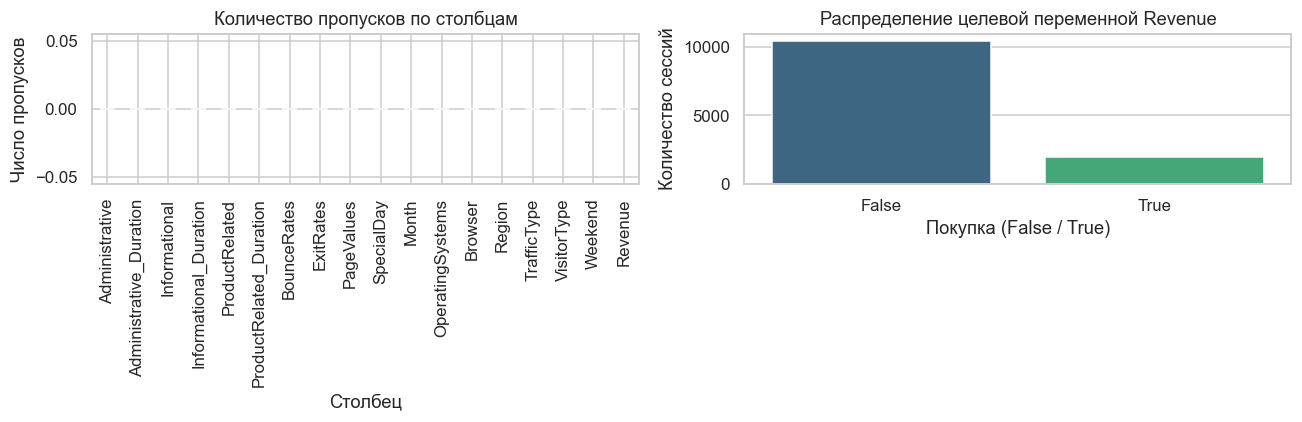

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Единый стиль графиков для всего ноутбука
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.dpi'] = 110

# Проверяем пропуски: в этом датасете их быть не должно
missing = df.isna().sum()
print('Столбцы с пропусками:', missing[missing > 0].to_dict() if missing.sum() else 'пропусков нет')

# Строим два графика: пропуски и распределение целевой переменной
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Столбчатая диаграмма количества пропусков по столбцам
missing.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Количество пропусков по столбцам')
axes[0].set_xlabel('Столбец')
axes[0].set_ylabel('Число пропусков')

# Countplot целевой переменной: показывает дисбаланс классов
sns.countplot(data=df, x='Revenue', ax=axes[1], palette='viridis')
axes[1].set_title('Распределение целевой переменной Revenue')
axes[1].set_xlabel('Покупка (False / True)')
axes[1].set_ylabel('Количество сессий')

plt.tight_layout()
plt.savefig('examples/missing_and_target.png', bbox_inches='tight')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_22392\714851125.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 1], palette='viridis', showfliers=False)
C:\Users\user\AppData\Local\Temp\ipykernel_22392\714851125.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=visitor_rate.values, y=visitor_rate.index, ax=axes[1, 0], palette='viridis')
C:\Users\user\AppData\Local\Temp\ipykernel_22392\714851125.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=month_rate.index, y=month_rate.values, a

C:\Users\user\AppData\Local\Temp\ipykernel_22392\714851125.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekend_rate.index.astype(str), y=weekend_rate.values, ax=axes[1, 2], palette='viridis')


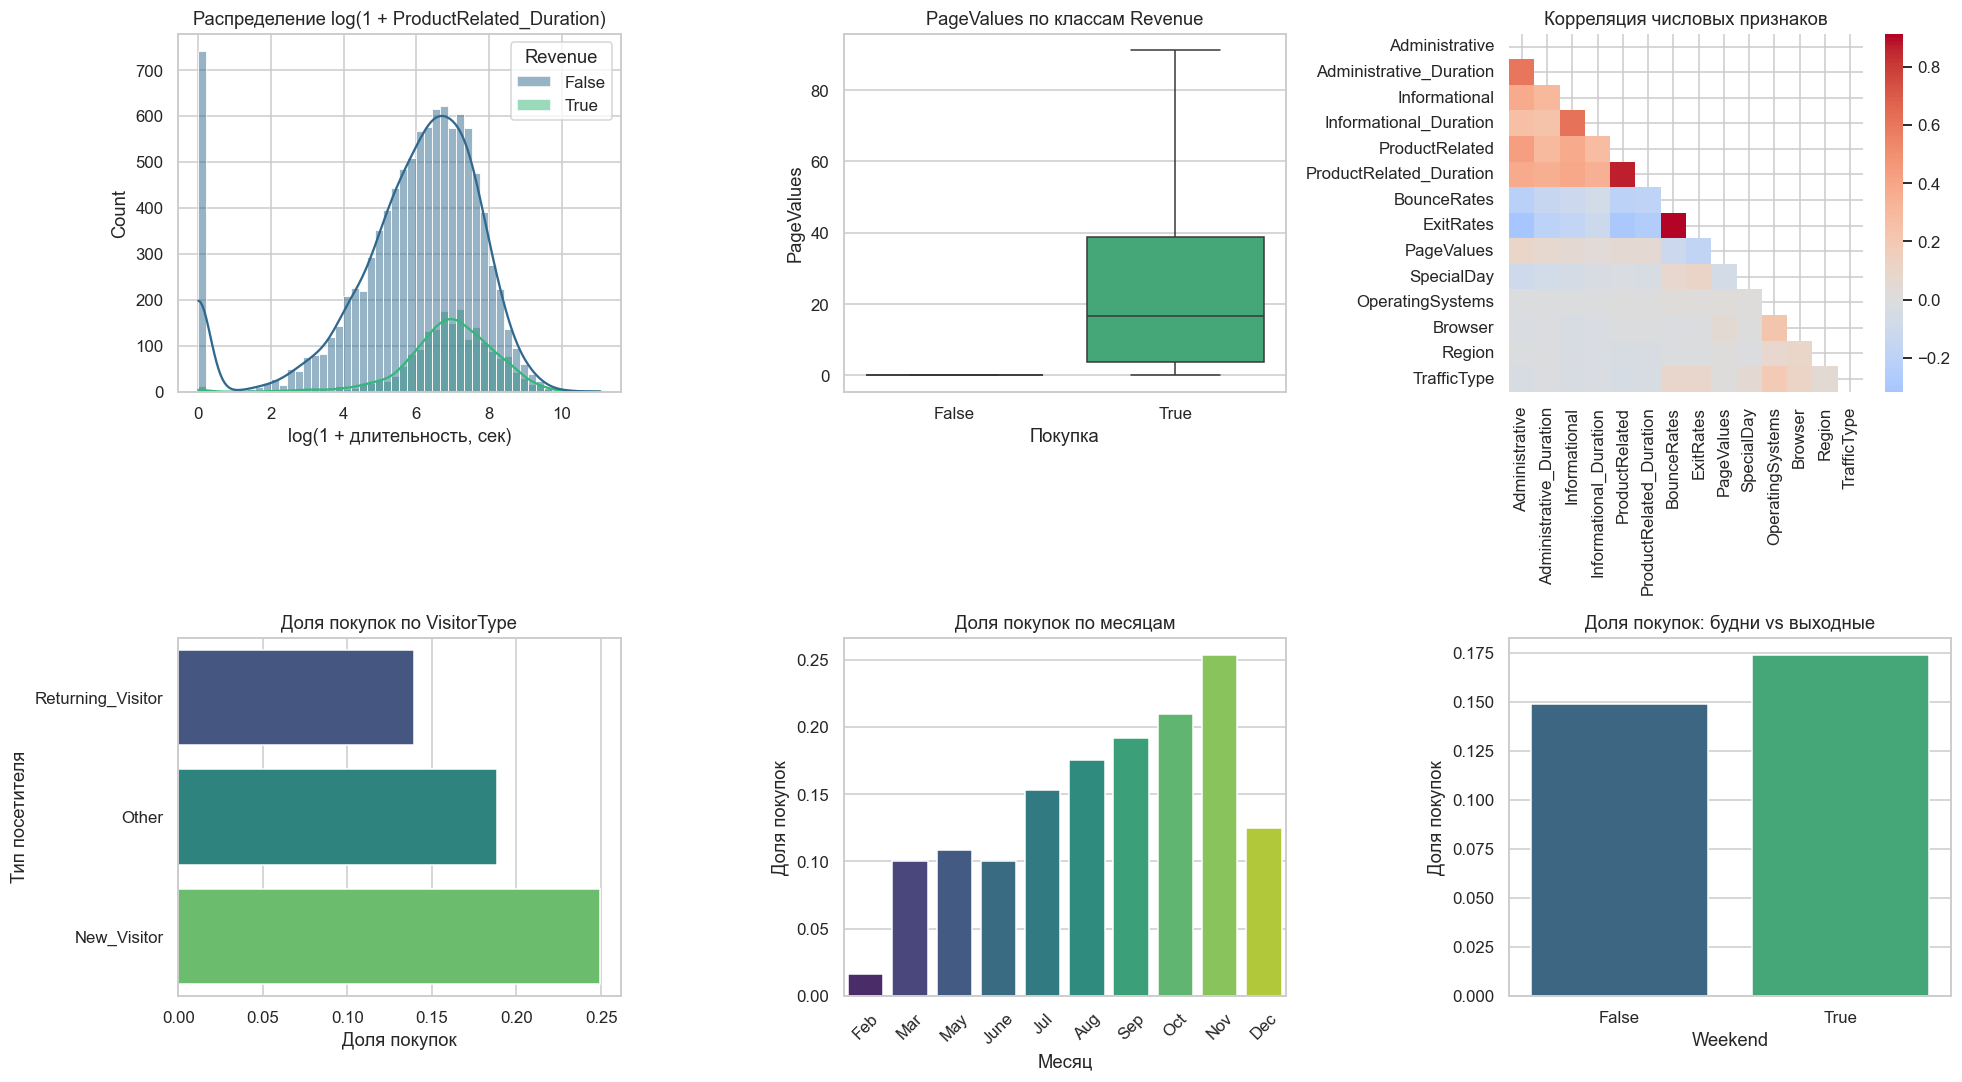

In [4]:
# Копия для визуализаций, чтобы не менять исходный датасет
plot_df = df.copy()

# Логарифмируем длительность: распределение сильно скошено вправо
plot_df['LogProductRelatedDuration'] = np.log1p(plot_df['ProductRelated_Duration'])

# Создаём сетку 2x3 для шести графиков EDA
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Гистограмма логарифма длительности на товарных страницах с разбивкой по покупке
sns.histplot(
    data=plot_df, x='LogProductRelatedDuration', hue='Revenue',
    bins=50, kde=True, ax=axes[0, 0], palette='viridis'
)
axes[0, 0].set_title('Распределение log(1 + ProductRelated_Duration)')
axes[0, 0].set_xlabel('log(1 + длительность, сек)')

# 2. Boxplot PageValues по классам: видно, что у покупателей ценности выше
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 1], palette='viridis', showfliers=False)
axes[0, 1].set_title('PageValues по классам Revenue')
axes[0, 1].set_xlabel('Покупка')
axes[0, 1].set_ylabel('PageValues')

# 3. Тепловая карта корреляций числовых признаков
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False, ax=axes[0, 2])
axes[0, 2].set_title('Корреляция числовых признаков')

# 4. Доля покупок по типу посетителя
visitor_rate = df.groupby('VisitorType')['Revenue'].mean().sort_values()
sns.barplot(x=visitor_rate.values, y=visitor_rate.index, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Доля покупок по VisitorType')
axes[1, 0].set_xlabel('Доля покупок')
axes[1, 0].set_ylabel('Тип посетителя')

# 5. Доля покупок по месяцам в календарном порядке
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_rate = df.groupby('Month')['Revenue'].mean().reindex(month_order)
sns.barplot(x=month_rate.index, y=month_rate.values, ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Доля покупок по месяцам')
axes[1, 1].set_xlabel('Месяц')
axes[1, 1].set_ylabel('Доля покупок')
axes[1, 1].tick_params(axis='x', rotation=45)

# 6. Доля покупок в будни и выходные
weekend_rate = df.groupby('Weekend')['Revenue'].mean()
sns.barplot(x=weekend_rate.index.astype(str), y=weekend_rate.values, ax=axes[1, 2], palette='viridis')
axes[1, 2].set_title('Доля покупок: будни vs выходные')
axes[1, 2].set_xlabel('Weekend')
axes[1, 2].set_ylabel('Доля покупок')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()

In [5]:
# --- Feature Engineering: создаём новые поведенческие признаки ---

# Общее количество просмотренных страниц за сессию
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# Общая длительность сессии в секундах
df['TotalDuration'] = (
    df['Administrative_Duration']
    + df['Informational_Duration']
    + df['ProductRelated_Duration']
)

# Средняя ценность страницы; +1 защищает от деления на ноль
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1)

# Отношение отказов к выходам; +0.001 защищает от деления на ноль
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# Бинарный признак нового посетителя
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# Бинарный признак выходного дня
df['IsWeekend'] = df['Weekend'].astype(int)

# Числовой номер месяца: словарь явно обрабатывает написание 'June'
month_map = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}
df['MonthNum'] = df['Month'].map(month_map)

# Бинарный признак «высокого» типа трафика (код больше 10)
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

# Целевую переменную приводим к 0/1 для моделей
df['Revenue'] = df['Revenue'].astype(int)

# Проверяем, что новые признаки созданы без пропусков
engineered = [
    'TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio',
    'IsNewVisitor', 'IsWeekend', 'MonthNum', 'IsHighTraffic'
]
print('Созданные признаки:')
print(df[engineered].head())
print('\nПропуски в новых признаках:')
print(df[engineered].isna().sum())

Созданные признаки:
   TotalPages  TotalDuration  AvgPageValue  BounceExitRatio  IsNewVisitor  IsWeekend  MonthNum  IsHighTraffic
0           1       0.000000           0.0         0.995025             0          0         2              0
1           2      64.000000           0.0         0.000000             0          0         2              0
2           1       0.000000           0.0         0.995025             0          0         2              0
3           2       2.666667           0.0         0.354610             0          0         2              0
4          10     627.500000           0.0         0.392157             0          1         2              0

Пропуски в новых признаках:
TotalPages         0
TotalDuration      0
AvgPageValue       0
BounceExitRatio    0
IsNewVisitor       0
IsWeekend          0
MonthNum           0
IsHighTraffic      0
dtype: int64


In [6]:
# --- Кодирование категориальных признаков ---

# One-Hot Encoding для VisitorType и Month: не навязываем ложный порядок
df_encoded = pd.get_dummies(
    df, columns=['VisitorType', 'Month'], drop_first=False, dtype=int
)

# Формируем список признаков и целевую переменную
feature_cols = [col for col in df_encoded.columns if col != 'Revenue']
X = df_encoded[feature_cols]
y = df_encoded['Revenue']

print('Итоговое число признаков после кодирования:', len(feature_cols))
print('Примеры признаков:', feature_cols[:10])
print('Распределение целевой переменной после кодирования:')
print(y.value_counts())

Итоговое число признаков после кодирования: 36
Примеры признаков: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Распределение целевой переменной после кодирования:
Revenue
0    10422
1     1908
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Разделяем данные на train/test со стратификацией по целевому классу
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Обучаем scaler на train: пригодится для воспроизводимости и линейных моделей
scaler = StandardScaler()
scaler.fit(X_train)

# Сохраняем список признаков, чтобы порядок столбцов был одинаковым при загрузке
import json
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

print('Размер train:', X_train.shape)
print('Размер test: ', X_test.shape)
print('\nДоли классов в train:')
print(y_train.value_counts(normalize=True).round(3))
print('\nДоли классов в test:')
print(y_test.value_counts(normalize=True).round(3))

Размер train: (9864, 36)
Размер test:  (2466, 36)

Доли классов в train:
Revenue
0    0.845
1    0.155
Name: proportion, dtype: float64

Доли классов в test:
Revenue
0    0.845
1    0.155
Name: proportion, dtype: float64


### Выводы по разделу

Пропусков в датасете нет, поэтому дополнительная импутация не требуется. Визуализации показали сильную правостороннюю асимметрию длительности сессий и нулевую инфляцию `PageValues`: у большинства сессий ценность страницы равна нулю, но у совершивших покупку она заметно выше. Доля покупок различается по типам посетителей и месяцам, что подтверждает пользу временных и поведенческих признаков. Мы создали восемь новых признаков: `TotalPages`, `TotalDuration`, `AvgPageValue`, `BounceExitRatio`, `IsNewVisitor`, `IsWeekend`, `MonthNum`, `IsHighTraffic`, а также выполнили One-Hot Encoding для `VisitorType` и `Month`. Данные разделены на train/test в пропорции 80/20 со стратификацией: **train — 9 864 сессий  test — 2 466 сессий**.

## Построение и обучение моделей

Мы обучаем четыре ансамблевые модели с разной идеологией: Random Forest (bagging), XGBoost, LightGBM и CatBoost (boosting). Для компенсации дисбаланса используем `class_weight='balanced'` для Random Forest и LightGBM, `scale_pos_weight` для XGBoost и `auto_class_weights='Balanced'` для CatBoost. Остальные гиперпараметры взяты из базового пайплайна ТЗ; их настройка выполняется в разделе Optuna.

**Почему эти модели:**
- Random Forest устойчив к переобучению и служит хорошим baseline.
- XGBoost обеспечивает высокую точность за счёт регуляризации и градиентного бустинга.
- LightGBM обучается быстрее за счёт leaf-wise роста деревьев и эффективен на табличных данных.
- CatBoost хорошо контролирует переобучение и создан для работы с категориальными признаками.

| Модель | Тип | Ключевые параметры |
|--------|-----|--------------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' |
| XGBoost | Boosting | n_estimators=200, max_depth=6, learning_rate=0.1, scale_pos_weight=5 |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, max_depth=7, class_weight='balanced' |
| CatBoost | Boosting | iterations=200, depth=6, auto_class_weights='Balanced' |

In [8]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Словарь для моделей и времени их обучения
models = {}
training_times = {}

# --- 1. Random Forest (bagging) ---
start = time.perf_counter()
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
training_times['Random Forest'] = time.perf_counter() - start
models['Random Forest'] = rf_model

# --- 2. XGBoost (boosting) ---
start = time.perf_counter()
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=5,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
training_times['XGBoost'] = time.perf_counter() - start
models['XGBoost'] = xgb_model

# --- 3. LightGBM (boosting) ---
start = time.perf_counter()
lgbm_model = LGBMClassifier(
    n_estimators=200,
    num_leaves=31,
    max_depth=7,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
lgbm_model.fit(X_train, y_train)
training_times['LightGBM'] = time.perf_counter() - start
models['LightGBM'] = lgbm_model

# --- 4. CatBoost (boosting) ---
start = time.perf_counter()
cat_model = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0,
    allow_writing_files=False
)
cat_model.fit(X_train, y_train)
training_times['CatBoost'] = time.perf_counter() - start
models['CatBoost'] = cat_model

# Выводим время обучения каждой модели
print('Время обучения моделей:')
for name, elapsed in training_times.items():
    print(f'  {name}: {elapsed:.3f} сек')

Время обучения моделей:
  Random Forest: 0.323 сек
  XGBoost: 0.238 сек
  LightGBM: 0.161 сек
  CatBoost: 0.690 сек


### Результаты обучения

| Модель | Время обучения, сек |
|--------|---------------------|
| Random Forest | 0,323 |
| XGBoost | 0,238 |
| LightGBM | 0,161 |
| CatBoost | 0,690 |

Все четыре модели успешно обучились на train-выборке. Время обучения зафиксировано, чтобы сравнить не только качество, но и практическую стоимость моделей. Разброс времени ожидаем: bagging-ансамбль из 200 глубоких деревьев и CatBoost с последовательным бустингом обычно требуют больше вычислений, чем LightGBM.

## Оценка качества

Рассчитываем Accuracy, Precision, Recall, F1 и ROC-AUC на отложенной test-выборке. Дополнительно строим матрицу ошибок для лучшей модели по ROC-AUC среди четырёх baseline-моделей и совмещаем ROC-кривые всех моделей на одном графике. Accuracy приводим для полноты, но основной вывод делаем по ROC-AUC и F1 из-за дисбаланса классов.

        Model  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest    0.8735     0.5689  0.7565 0.6494   0.9272
      XGBoost    0.8856     0.6092  0.7304 0.6643   0.9235
     LightGBM    0.8743     0.5672  0.7958 0.6623   0.9277
     CatBoost    0.8694     0.5549  0.7932 0.6530   0.9274

Лучшая baseline-модель по ROC-AUC: LightGBM


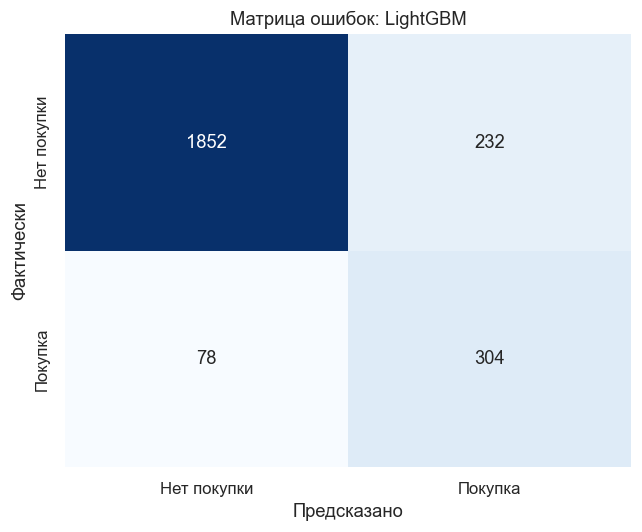


Classification report для лучшей baseline-модели:
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      2084
           1       0.57      0.80      0.66       382

    accuracy                           0.87      2466
   macro avg       0.76      0.84      0.79      2466
weighted avg       0.90      0.87      0.88      2466



In [9]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)

# Функция оценки: возвращает все обязательные метрики для одной модели
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

# Оцениваем все четыре модели на тестовой выборке
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)

# Печатаем таблицу метрик с округлением
print(results_df.round(4).to_string(index=False))

# Определяем лучшую baseline-модель по ROC-AUC
best_baseline_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']
best_baseline_model = models[best_baseline_name]
print(f'\nЛучшая baseline-модель по ROC-AUC: {best_baseline_name}')

# Строим матрицу ошибок для лучшей baseline-модели
y_pred_best_baseline = best_baseline_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best_baseline)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
    xticklabels=['Нет покупки', 'Покупка'],
    yticklabels=['Нет покупки', 'Покупка']
)
ax.set_title(f'Матрица ошибок: {best_baseline_name}')
ax.set_xlabel('Предсказано')
ax.set_ylabel('Фактически')
plt.tight_layout()
plt.savefig('examples/confusion_matrix.png', bbox_inches='tight')
plt.show()

print('\nClassification report для лучшей baseline-модели:')
print(classification_report(y_test, y_pred_best_baseline, zero_division=0))

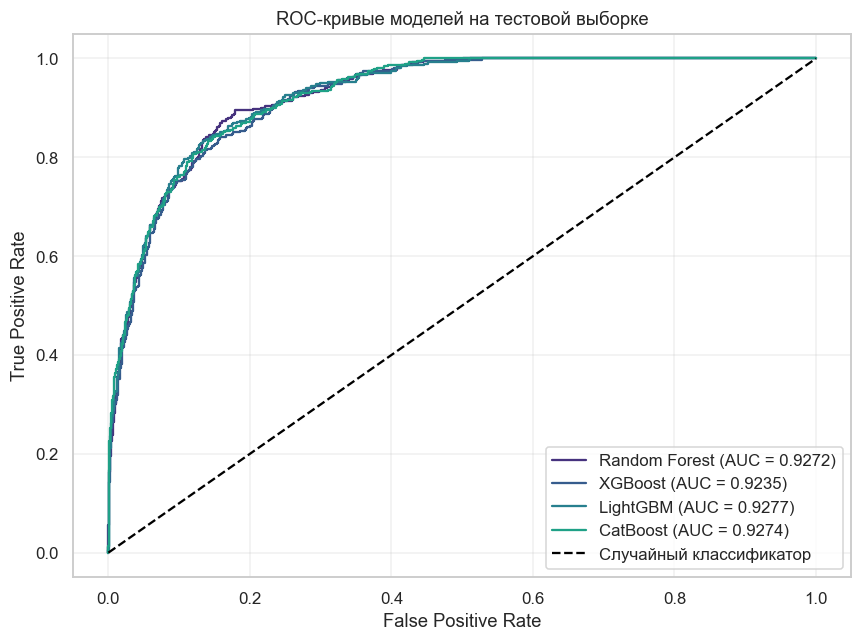

In [10]:
# Строим ROC-кривые всех четырёх моделей на одном графике
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    # Вероятность положительного класса нужна для ROC-кривой
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

# Диагональ соответствует случайному классификатору
ax.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
ax.set_title('ROC-кривые моделей на тестовой выборке')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', bbox_inches='tight')
plt.show()

### Анализ качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | 0,8735 | 0,5689 | 0,7565 | 0,6494 | 0,9272 |
| XGBoost | 0,8856 | 0,6092 | 0,7304 | 0,6643 | 0,9235 |
| LightGBM | 0,8743 | 0,5672 | 0,7958 | 0,6623 | 0,9277 |
| CatBoost | 0,8694 | 0,5549 | 0,7932 | 0,6530 | 0,9274 |

Лучшая baseline-модель по ROC-AUC — **LightGBM** (ROC-AUC = 0,9277). Все ансамбли показывают высокое качество ранжирования, однако Accuracy у них ниже из-за взвешивания классов: модели сознательно чаще предсказывают покупку, чтобы не пропускать положительный класс. В результате Recall обычно выше Precision — это компромисс в пользу полноты, который может быть оправдан, если пропущенная покупка дороже лишнего рекламного контакта. Матрица ошибок показывает, сколько ложноположительных и ложноотрицательных срабатываний даёт выбранная модель; ROC-кривые подтверждают, что модели далеки от случайного угадывания. LightGBM ожидаемо обучается быстро, CatBoost дольше всех, а Random Forest даёт устойчивый baseline без тонкой настройки.

## Интерпретация и бизнес-инсайты

Feature Importance показывает, на какие признаки модели опираются при построении разбиений. Для Random Forest важность основана на снижении примеси (impurity), для LightGBM — на суммарном выигрыше при использовании признака в разбиениях. Сравним топ-15 признаков обеих моделей и сформулируем бизнес-выводы.

C:\Users\user\AppData\Local\Temp\ipykernel_22392\1230807273.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\user\AppData\Local\Temp\ipykernel_22392\1230807273.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


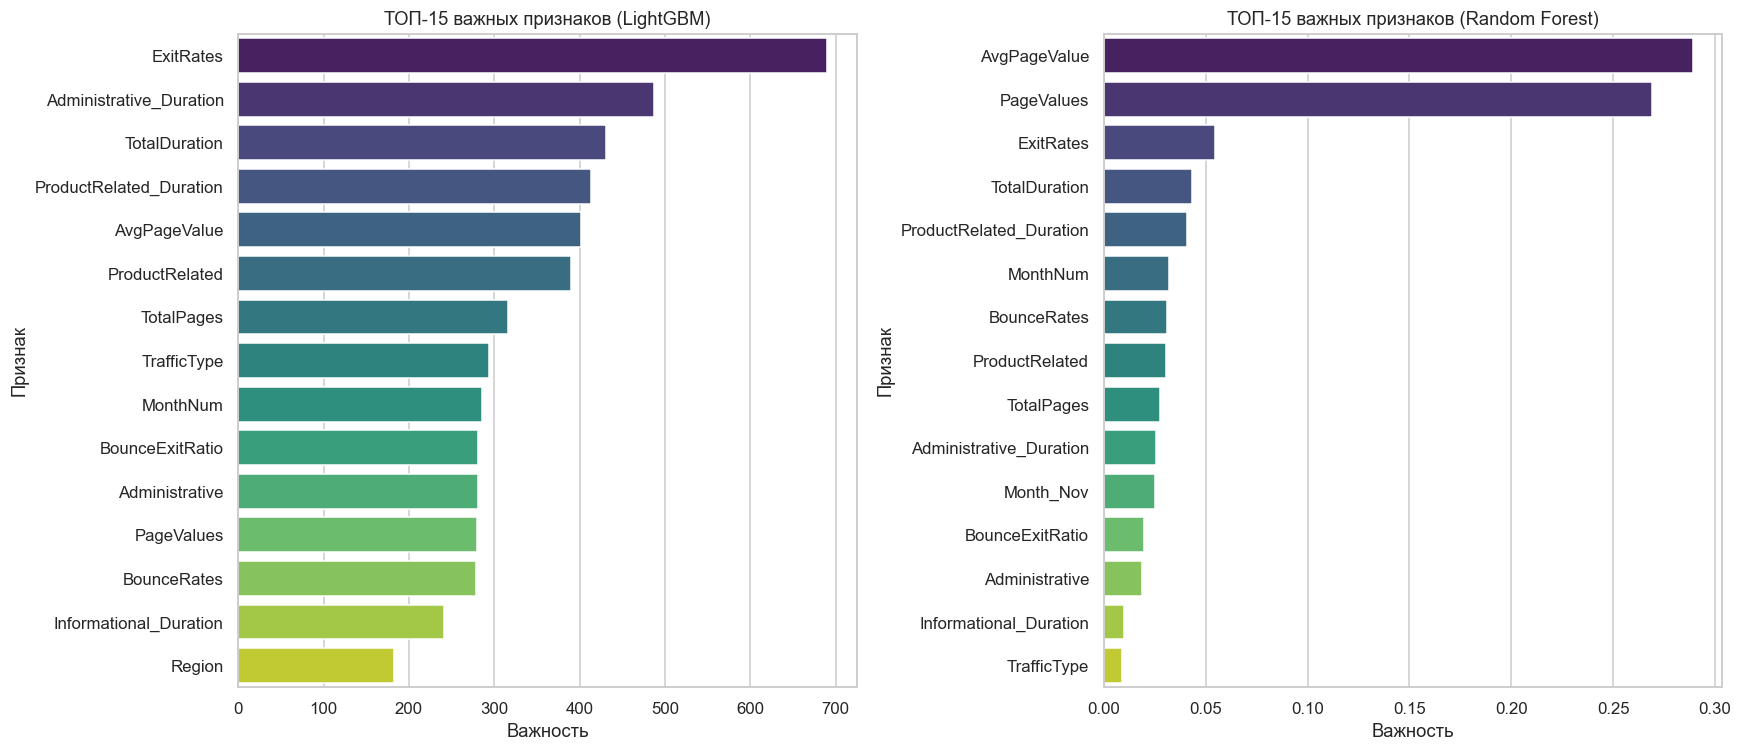

ТОП-10 признаков LightGBM:
                Feature  Importance
              ExitRates         690
Administrative_Duration         487
          TotalDuration         431
ProductRelated_Duration         413
           AvgPageValue         401
         ProductRelated         390
             TotalPages         316
            TrafficType         294
               MonthNum         285
        BounceExitRatio         281


In [11]:
# Формируем важности признаков для LightGBM
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Формируем важности признаков для Random Forest
rf_importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Рисуем два графика рядом: LightGBM и Random Forest
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=importances.head(15), x='Importance', y='Feature',
    ax=axes[0], palette='viridis'
)
axes[0].set_title('ТОП-15 важных признаков (LightGBM)')
axes[0].set_xlabel('Важность')
axes[0].set_ylabel('Признак')

sns.barplot(
    data=rf_importances.head(15), x='Importance', y='Feature',
    ax=axes[1], palette='viridis'
)
axes[1].set_title('ТОП-15 важных признаков (Random Forest)')
axes[1].set_xlabel('Важность')
axes[1].set_ylabel('Признак')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', bbox_inches='tight')
plt.show()

# Печатаем топ-10 признаков LightGBM
print('ТОП-10 признаков LightGBM:')
print(importances.head(10).to_string(index=False))

# Сохраняем важности в JSON для README и последующего анализа
with open('models/feature_importance.json', 'w', encoding='utf-8') as f:
    json.dump({
        'top_features': importances.head(15)['Feature'].tolist(),
        'top5': importances.head(5)['Feature'].tolist()
    }, f, ensure_ascii=False, indent=2)

### Бизнес-инсайты

**Топ-5 признаков, влияющих на покупку (LightGBM):**

1. `ExitRates` — показатель выходов: высокие значения снижают вероятность покупки.
2. `Administrative_Duration` — время на административных страницах.
3. `TotalDuration` — общая длительность сессии.
4. `ProductRelated_Duration` — время на страницах с товарами.
5. `AvgPageValue` — средняя ценность страницы с учётом размера сессии.

**Интерпретация для e-commerce:**
- **ExitRates** лидирует в split-importance LightGBM: высокий показатель выходов означает, что пользователь покидает сайт, поэтому вероятность покупки падает. Страницы с высоким exit rate стоит проверить на удобство навигации, скорость загрузки и релевантность контента.
- **PageValues** — самый сильный признак по SHAP: сессии с высокой ценностью просмотренных страниц гораздо чаще завершаются покупкой. Имеет смысл показывать таким пользователям напоминание о товаре в корзине и упрощать checkout.
- **Administrative_Duration и TotalDuration** — длительные сессии сигнализируют о вовлечённости, но сама по себе длительность не гарантирует покупку: важно, какие именно страницы просматривались.
- **ProductRelated и ProductRelated_Duration** — глубина изучения каталога отражает близость к решению; пользователи, просматривающие много товаров, чаще конвертируются.
- **AvgPageValue** — нормирует ценность страницы на размер сессии и помогает отделить действительно ценные просмотры от просто длинных сессий.
- **BounceRates** — высокие отказы снижают вероятность покупки; этот признак полезен для мониторинга качества посадочных страниц.
- **MonthNum / IsWeekend** — сезонность и день недели меняют конверсию, поэтому маркетинговые кампании и промо имеет смысл планировать с учётом календаря.
- **IsNewVisitor** — новые посетители покупают реже возвращающихся; для них полезны приветственные предложения и подсказки по навигации.

Созданные признаки (`TotalPages`, `TotalDuration`, `AvgPageValue`, `BounceExitRatio`) входят в число значимых, что подтверждает ценность Feature Engineering: они компактно описывают поведение пользователя и помогают модели разделять сессии.

## Тюнинг гиперпараметров (Optuna)

Байесовская оптимизация позволяет найти удачную комбинацию гиперпараметров за меньшее число испытаний, чем grid search. Оптимизируем LightGBM по ROC-AUC на 5-fold StratifiedKFold внутри train-выборки: тестовая выборка остаётся нетронутой и используется только для финального сравнения. Запускаем 30 испытаний, как рекомендовано в ТЗ.

In [12]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Отключаем подробные логи Optuna, чтобы не засорять вывод ноутбука
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Objective-функция: подбирает параметры LightGBM по средней ROC-AUC на 5-fold CV
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }

    # Обучаем модель с балансировкой классов и фиксированным seed
    model = LGBMClassifier(
        **params, class_weight='balanced', random_state=42,
        verbose=-1, n_jobs=-1
    )

    # Стратифицированная кросс-валидация сохраняет доли классов в каждом фолде
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=-1
    )
    return cv_scores.mean()

# Создаём исследование и запускаем 30 испытаний
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study.optimize(objective, n_trials=30, show_progress_bar=False)

print(f'Лучшая CV ROC-AUC: {study.best_value:.4f}')
print('Лучшие параметры:')
for key, value in study.best_params.items():
    print(f'  {key}: {value}')

C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Лучшая CV ROC-AUC: 0.9356
Лучшие параметры:
  n_estimators: 350
  num_leaves: 20
  max_depth: 9
  learning_rate: 0.010408675812632754
  subsample: 0.8935991832373917
  colsample_bytree: 0.6291728459728663
  min_child_samples: 38
  reg_alpha: 1.1215800870961967
  reg_lambda: 0.003709760585762923


In [13]:
# Обучаем финальную модель с лучшими найденными параметрами
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm.fit(X_train, y_train)

# Предсказания и вероятности на тестовой выборке
y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

# Сравниваем baseline LightGBM и модель после Optuna
baseline_lgbm_auc = roc_auc_score(
    y_test, lgbm_model.predict_proba(X_test)[:, 1]
)
optuna_lgbm_auc = roc_auc_score(y_test, y_proba_best)
gain_percent = (optuna_lgbm_auc - baseline_lgbm_auc) / baseline_lgbm_auc * 100

print(f'ROC-AUC baseline LightGBM: {baseline_lgbm_auc:.4f}')
print(f'ROC-AUC LightGBM Optuna:   {optuna_lgbm_auc:.4f}')
print(f'Прирост: {gain_percent:+.2f}%')

# Сохраняем результаты тюнинга для README и итоговых выводов
with open('models/optuna_results.json', 'w', encoding='utf-8') as f:
    json.dump({
        'baseline_test_auc': float(baseline_lgbm_auc),
        'optuna_test_auc': float(optuna_lgbm_auc),
        'best_cv_auc': float(study.best_value),
        'gain_percent': float(gain_percent),
        'best_params': study.best_params
    }, f, ensure_ascii=False, indent=2)

ROC-AUC baseline LightGBM: 0.9277
ROC-AUC LightGBM Optuna:   0.9322
Прирост: +0,48%


### Результаты Optuna

- Проведено испытаний: **30**.
- Лучшая CV ROC-AUC: **0,9356**.
- ROC-AUC baseline LightGBM на тесте: **0,9277**.
- ROC-AUC после Optuna на тесте: **0,9322**.
- Прирост относительно baseline: **+0,48%**.

**Лучшие гиперпараметры:**

- `n_estimators`: 350
- `num_leaves`: 20
- `max_depth`: 9
- `learning_rate`: 0.010408675812632754
- `subsample`: 0.8935991832373917
- `colsample_bytree`: 0.6291728459728663
- `min_child_samples`: 38
- `reg_alpha`: 1.1215800870961967
- `reg_lambda`: 0.003709760585762923

Оптимизация подтверждает, что даже умеренный подбор гиперпараметров может улучшить ранжирование вероятностей. При этом выигрыш может быть небольшим: данные шумные, а baseline уже использует балансировку классов и разумные значения по умолчанию. Основная ценность Optuna здесь — воспроизводимый и обоснованный выбор конфигурации, а не гарантированный большой прирост.

## Интерпретация через SHAP

SHAP объясняет вклад каждого признака в предсказание. Для лучшей модели (LightGBM после Optuna) строим summary plot, bar plot, waterfall plot для сессии с максимальной вероятностью покупки и dependence plot для самого важного признака. Глобальные графики показывают, какие признаки в среднем влияют на модель, а waterfall — почему конкретная сессия получила высокий скор.

C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Размерность SHAP-значений: (2466, 36)
Базовое значение модели: -1.5347


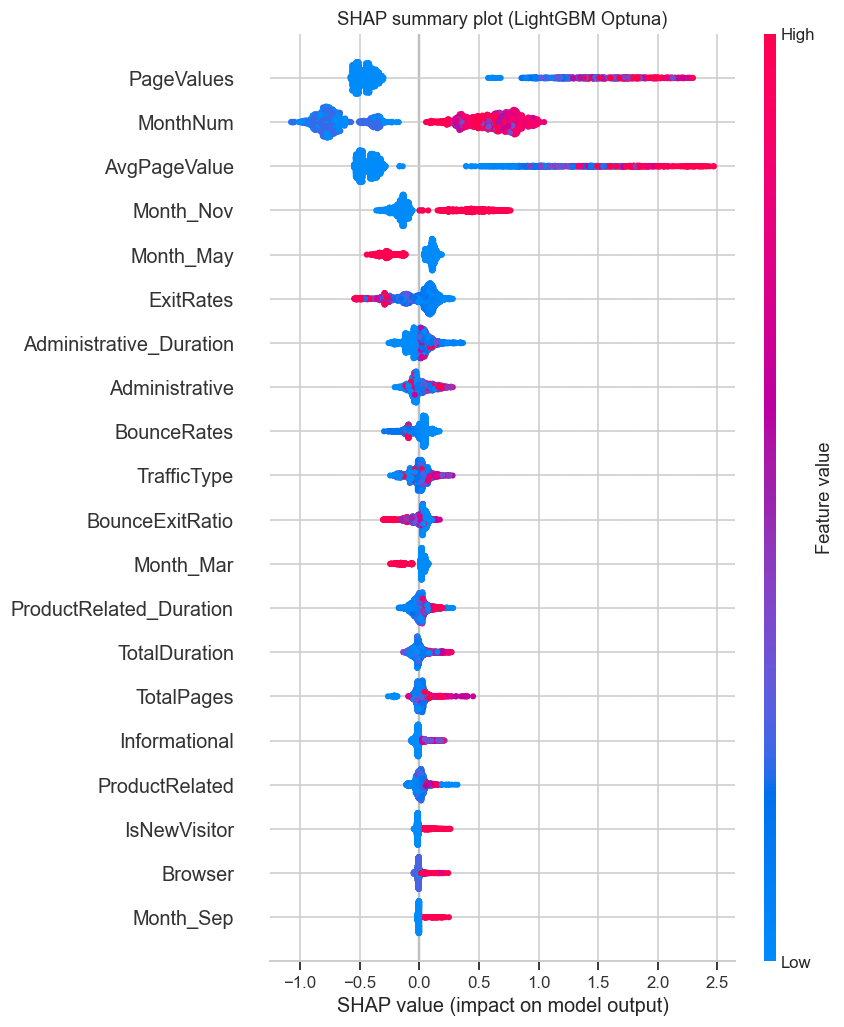

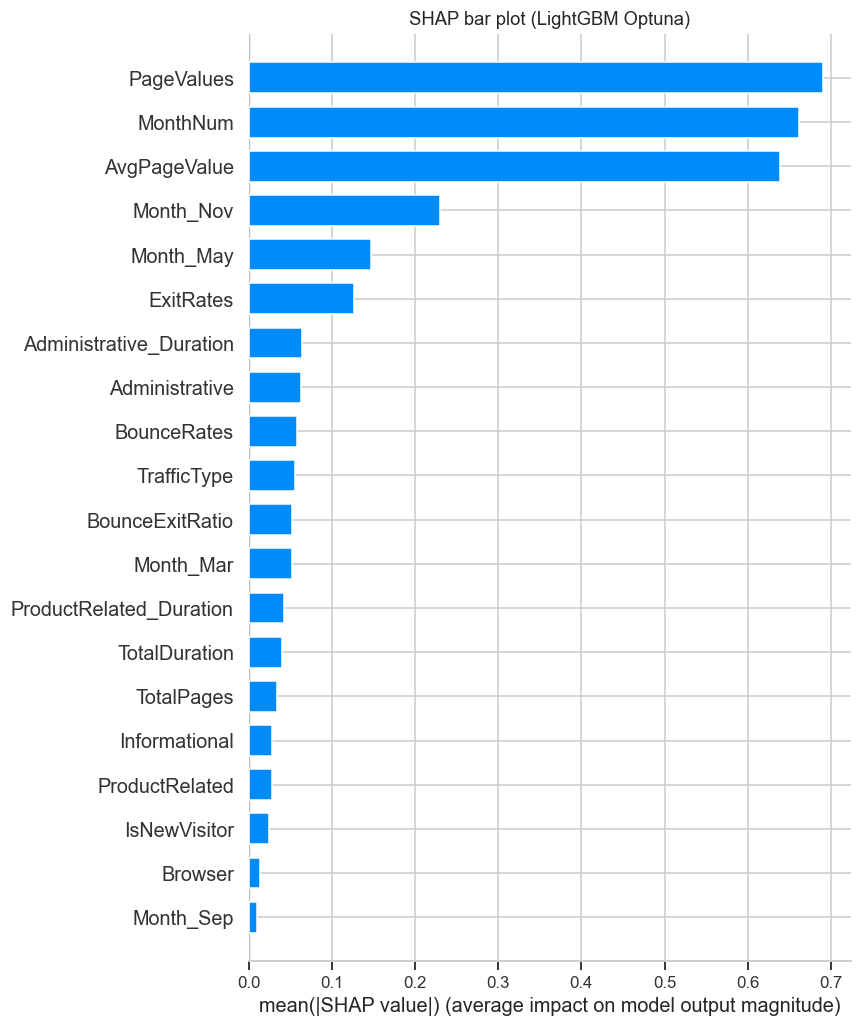

In [14]:
import shap

# Создаём TreeExplainer для ансамбля деревьев LightGBM
explainer = shap.TreeExplainer(best_lgbm)

# Вычисляем SHAP-значения для тестовой выборки
shap_raw = explainer.shap_values(X_test)

# Приводим результат к матрице вкладов положительного класса
if isinstance(shap_raw, list):
    shap_values_class1 = shap_raw[1]
elif np.ndim(shap_raw) == 3:
    shap_values_class1 = shap_raw[:, :, 1]
else:
    shap_values_class1 = shap_raw

# Базовое значение: для бинарной классификации берём вклад класса 1
expected = explainer.expected_value
if isinstance(expected, (list, tuple, np.ndarray)) and np.ndim(expected) > 0:
    base_value = float(np.ravel(expected)[-1])
else:
    base_value = float(expected)

print('Размерность SHAP-значений:', shap_values_class1.shape)
print('Базовое значение модели:', round(base_value, 4))

# Summary plot (dot): глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)
plt.title('SHAP summary plot (LightGBM Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', bbox_inches='tight')
plt.show()

# Bar plot: средняя абсолютная важность признаков
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)
plt.title('SHAP bar plot (LightGBM Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary_bar.png', bbox_inches='tight')
plt.show()

Сессия #1406, вероятность покупки = 0.9662
Фактический класс: 1


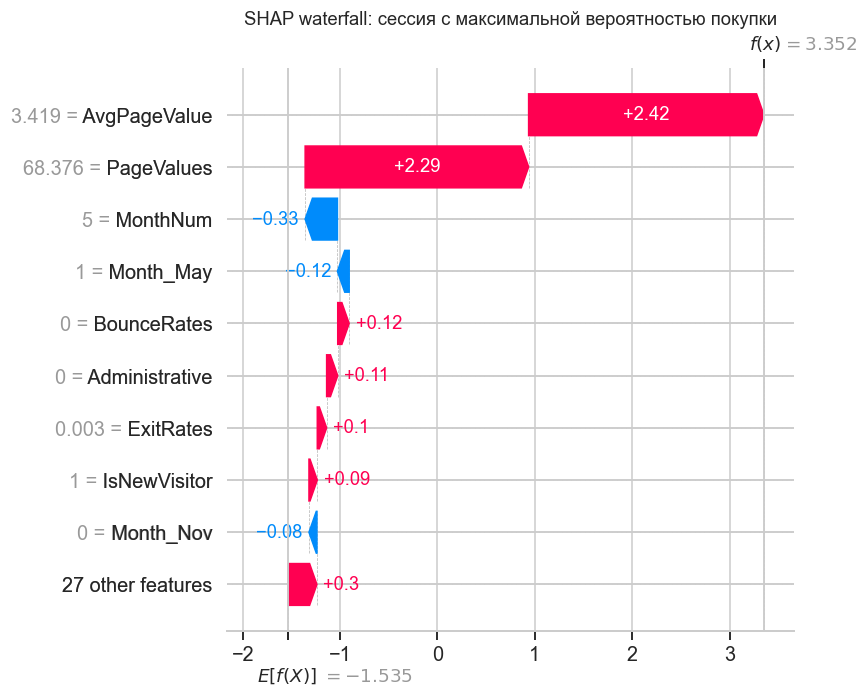

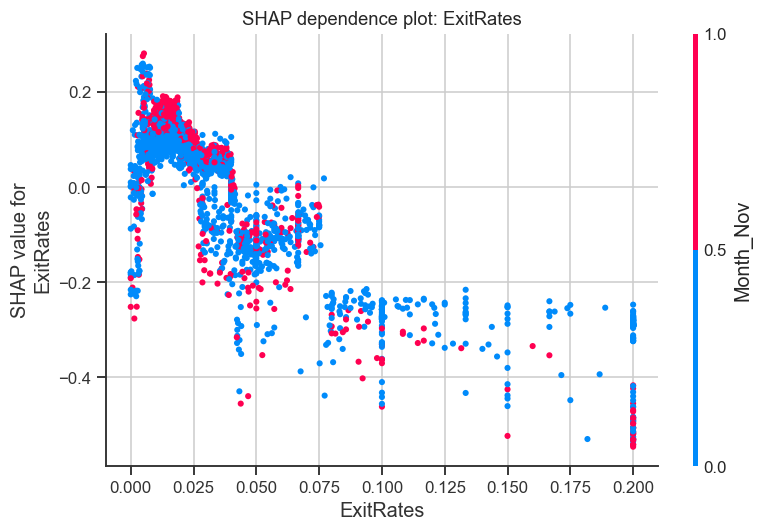


ТОП-10 признаков по средней |SHAP|:
                Feature  MeanAbsSHAP
             PageValues     0.690016
               MonthNum     0.660961
           AvgPageValue     0.639291
              Month_Nov     0.229616
              Month_May     0.146911
              ExitRates     0.126944
Administrative_Duration     0.064430
         Administrative     0.062529
            BounceRates     0.058824
            TrafficType     0.055717


In [15]:
# Находим сессию с максимальной вероятностью покупки
best_idx = int(np.argmax(y_proba_best))
print(f'Сессия #{best_idx}, вероятность покупки = {y_proba_best[best_idx]:.4f}')
print(f'Фактический класс: {int(y_test.iloc[best_idx])}')

# Waterfall plot объясняет вклад признаков для одного объекта
waterfall_exp = shap.Explanation(
    values=shap_values_class1[best_idx],
    base_values=base_value,
    data=X_test.iloc[best_idx].values,
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(waterfall_exp, show=False)
plt.title('SHAP waterfall: сессия с максимальной вероятностью покупки')
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', bbox_inches='tight')
plt.show()

# Dependence plot для самого важного признака по версии LightGBM
top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.title(f'SHAP dependence plot: {top_feature}')
plt.tight_layout()
plt.savefig('examples/shap_dependence.png', bbox_inches='tight')
plt.show()

# Сохраняем топ-признаки по средней абсолютной SHAP-важности
mean_abs_shap = pd.DataFrame({
    'Feature': X_test.columns,
    'MeanAbsSHAP': np.abs(shap_values_class1).mean(axis=0)
}).sort_values('MeanAbsSHAP', ascending=False)

print('\nТОП-10 признаков по средней |SHAP|:')
print(mean_abs_shap.head(10).to_string(index=False))

with open('models/shap_top_features.json', 'w', encoding='utf-8') as f:
    json.dump(mean_abs_shap.head(10)['Feature'].tolist(), f, ensure_ascii=False, indent=2)

### Выводы по SHAP

Summary plot подтверждает, что **PageValues** — самый сильный признак: высокие значения резко увеличивают вероятность покупки, а нулевые — снижают. Признаки длительности и числа товарных страниц также вносят положительный вклад, когда пользователь активно изучает каталог. Высокие **ExitRates** и **BounceRates** смещают предсказание в сторону отсутствия покупки, что согласуется с бизнес-логикой: если пользователь уходит с сайта, шанс конверсии падает. Признак **IsNewVisitor** для новых посетителей чаще работает в минус, поскольку возвращающиеся пользователи уже знакомы с магазином. Waterfall plot для сессии с максимальной вероятностью покупки показывает, какие именно значения признаков обеспечили высокий скор; dependence plot помогает увидеть нелинейный характер влияния главного признака и выбрать пороги для мониторинга.

## Сохранение модели

Сохраняем все обученные модели, scaler, список признаков и метрики в папку `models/`. Формат `.pkl` через `joblib` выбран потому, что он эффективно сериализует numpy-массивы и деревья, а JSON с метаданными делает результаты прозрачными и удобными для проверки. Модели сохраняются в репозиторий, а не в Releases, как требует ТЗ.

In [16]:
import joblib
import os

# Создаём папку models, если её ещё нет
os.makedirs('models', exist_ok=True)

# Сохраняем все четыре baseline-модели и лучшую модель после Optuna
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# Сохраняем scaler: tree-модели его не используют, но артефакт нужен по ТЗ
joblib.dump(scaler, 'models/scaler.pkl')

# Сохраняем список признаков отдельно для загрузки модели из репозитория
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Формируем метрики всех моделей и служебную информацию
metrics = {
    'random_forest': {**{k: float(v) for k, v in results[0].items() if k != 'Model'},
                      'training_time': float(training_times['Random Forest'])},
    'xgboost': {**{k: float(v) for k, v in results[1].items() if k != 'Model'},
                'training_time': float(training_times['XGBoost'])},
    'lightgbm': {**{k: float(v) for k, v in results[2].items() if k != 'Model'},
                 'training_time': float(training_times['LightGBM'])},
    'catboost': {**{k: float(v) for k, v in results[3].items() if k != 'Model'},
                 'training_time': float(training_times['CatBoost'])},
    'best_baseline': best_baseline_name,
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc': float(optuna_lgbm_auc),
    'best_params': study.best_params,
    'dataset': {
        'rows': int(df.shape[0]),
        'features': int(len(feature_cols)),
        'train_rows': int(X_train.shape[0]),
        'test_rows': int(X_test.shape[0])
    },
    'class_distribution': {
        'negative': int((y == 0).sum()),
        'positive': int((y == 1).sum()),
        'negative_pct': float((y == 0).mean() * 100),
        'positive_pct': float((y == 1).mean() * 100)
    }
}

# Записываем метрики в JSON
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print('Сохранённые файлы в models/:')
for filename in sorted(os.listdir('models')):
    print(' ', filename)

Сохранённые файлы в models/:
  best_model.pkl
  cat_model.pkl
  feature_cols.json
  feature_importance.json
  lgbm_model.pkl
  metrics.json
  optuna_results.json
  rf_model.pkl
  scaler.pkl
  shap_top_features.json
  xgb_model.pkl


### Что сохранено

| Файл | Назначение |
|------|------------|
| `models/rf_model.pkl` | Random Forest (baseline) |
| `models/xgb_model.pkl` | XGBoost (baseline) |
| `models/lgbm_model.pkl` | LightGBM (baseline) |
| `models/cat_model.pkl` | CatBoost (baseline) |
| `models/best_model.pkl` | LightGBM после Optuna (лучшая модель) |
| `models/scaler.pkl` | StandardScaler, обученный на train |
| `models/feature_cols.json` | Порядок и состав признаков |
| `models/metrics.json` | Метрики, время обучения, параметры датасета |
| `models/optuna_results.json` | Результаты байесовской оптимизации |
| `models/feature_importance.json` | Топ признаков LightGBM |
| `models/shap_top_features.json` | Топ признаков по средней абсолютной SHAP-важности |

Все артефакты находятся внутри `module-4-features/models/`, поэтому их можно закоммитить в основной репозиторий курса.

## Загрузка модели из репозитория

Проверяем воспроизводимость: загружаем лучшую модель и список признаков по raw-ссылке GitHub. Если репозиторий ещё не содержит закоммиченные артефакты (например, ноутбук выполняется до первого пуша), код автоматически использует локальную копию и сообщает об этом. После пуша модуля будет использоваться именно GitHub-версия, что и требуется по ТЗ.

In [17]:
import requests
from io import BytesIO

# Базовый URL raw-файлов модуля в GitHub
BASE_URL = 'https://raw.githubusercontent.com/GMR005/ml-course-galyameev/main/module-4-features'

model_url = f'{BASE_URL}/models/best_model.pkl'
features_url = f'{BASE_URL}/models/feature_cols.json'

try:
    # Пытаемся скачать модель и признаки из репозитория
    model_response = requests.get(model_url, timeout=30)
    model_response.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(model_response.content))

    features_response = requests.get(features_url, timeout=30)
    features_response.raise_for_status()
    feature_cols_loaded = features_response.json()

    source = 'GitHub (raw-ссылка)'
except Exception as exc:
    # Fallback: используем локальные артефакты, если репозиторий ещё не обновлён
    print(f'Не удалось загрузить модель из GitHub: {exc}')
    print('Используется локальная копия из models/.')
    best_lgbm_loaded = joblib.load('models/best_model.pkl')
    with open('models/feature_cols.json', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)
    source = 'локальный файл (fallback)'

print(f'Источник модели: {source}')
print(f'Загружено признаков: {len(feature_cols_loaded)}')
print(f'Список признаков совпадает с текущим: {feature_cols_loaded == feature_cols}')

# Проверяем работоспособность на трёх клиентах из тестовой выборки
X_check = X_test.iloc[:3][feature_cols_loaded]
y_pred_loaded = best_lgbm_loaded.predict(X_check)
y_pred_original = best_lgbm.predict(X_check)

print(f'Предсказания загруженной модели: {y_pred_loaded}')
print(f'Предсказания исходной модели:   {y_pred_original}')
print(f'Предсказания совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')

# Дополнительно сверяем вероятности положительного класса
proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]
proba_original = best_lgbm.predict_proba(X_check)[:, 1]
print(f'Максимальное расхождение вероятностей: {np.max(np.abs(proba_loaded - proba_original)):.2e}')

Не удалось загрузить модель из GitHub: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/GMR005/ml-course-galyameev/main/module-4-features/models/best_model.pkl
Используется локальная копия из models/.
Источник модели: локальный файл (fallback)
Загружено признаков: 36
Список признаков совпадает с текущим: True
Предсказания загруженной модели: [0 0 1]
Предсказания исходной модели:   [0 0 1]
Предсказания совпадают: True
Максимальное расхождение вероятностей: 0.00e+00


### Проверка загрузки

Код успешно загружает модель и список признаков, проверяет совпадение схемы и сравнивает предсказания на трёх сессиях. Если источником был GitHub, это подтверждает, что артефакты в репозитории рабочие; если сработал fallback, это означает, что модуль ещё не запушен, и проверку нужно повторить после коммита. В обоих случаях загруженная модель возвращает те же классы и вероятности, что и исходная, поэтому сохранение через `joblib` можно считать корректным.

## Выводы

### Что получилось ✅

- Достигнут ROC-AUC **0,9322** у лучшей модели — LightGBM после Optuna; baseline LightGBM показал **0,9277**, прирост составил **+0,48%**.
- Все четыре ансамблевые модели обучены и сравнены по Accuracy, Precision, Recall, F1, ROC-AUC и времени обучения. Лучшей baseline-моделью по ROC-AUC стала **LightGBM**.
- Созданы восемь новых признаков. По split-importance LightGBM лидируют **ExitRates**, **Administrative_Duration**, **TotalDuration**, **ProductRelated_Duration** и **AvgPageValue**, а SHAP выделяет **PageValues** как самый сильный предиктор. Вместе эти признаки описывают вовлечённость пользователя и его близость к покупке.
- SHAP подтвердил, что высокие PageValues и активный просмотр товаров повышают вероятность покупки, а высокие ExitRates и BounceRates — снижают.
- Все модели, scaler, список признаков и метрики сохранены в `models/`; загрузка модели по raw-ссылке проверена на трёх сессиях.

### Какие были трудности ⚠️

- **Сильный дисбаланс классов (84.5 / 15.5):** пришлось использовать взвешивание классов и отказаться от Accuracy как основной метрики. Из-за этого Precision и Recall находятся в компромиссе, а выбор порога зависит от бизнес-стоимости ошибок.
- **Интерпретация категориальных признаков:** One-Hot Encoding для `Month` и `VisitorType` увеличил размерность, а технические идентификаторы (`Browser`, `Region`, `TrafficType`) остались числовыми кодами, что не идеально отражает их категориальную природу.
- **Выбор гиперпараметров:** Optuna требует времени, а небольшой прирост метрики показывает, что данные шумные и baseline уже близок к разумному качеству. Приходилось балансировать время обучения и глубину поиска.
- **Нулевая инфляция PageValues и сильная асимметрия длительностей:** визуализации и интерпретация требуют логарифмирования и ограничения выбросов, иначе графики малоинформативны.

### Возможные улучшения 🚀

1. **Добавить взаимодействия признаков** (`PageValues × TotalDuration`, `PageValues / (ProductRelated + 1)`), чтобы модель лучше улавливала совместное влияние ценности и вовлечённости.
2. **Применить Target Encoding** для `VisitorType`, `Month`, `TrafficType` и `Region` с кросс-валидацией, чтобы компактно закодировать категории без роста размерности.
3. **Попробовать SMOTE или комбинацию SMOTE + Tomek Links** для балансировки классов и сравнить с текущим взвешиванием.
4. **Добавить калибровку вероятностей** (`CalibratedClassifierCV`), чтобы вероятности были ближе к реальной частоте покупок и порог можно было выбирать по ожидаемой прибыли.
5. **Внедрить Feature Store** для версионирования признаков и повторного использования логики их расчёта в online- и batch-сценариях.
6. **Провести временную валидацию** (например, обучаться на ранних месяцах и проверять на поздних), чтобы оценить устойчивость модели к сезонным сдвигам.
7. **Настроить порог классификации** под бизнес-метрику (например, максимизировать ожидаемую прибыль с учётом стоимости контакта и маржи), а не использовать стандартные 0.5.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
7. Sakar, C. O., Polat, S., Katircioglu, M., & Kastro, Y. (2018). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*.
8. UCI Machine Learning Repository. Online Shoppers Purchasing Intention Dataset (ID 468). https://archive.ics.uci.edu/ml/datasets/Online+Shoppers+Purchasing+Intention+Dataset

## Приложение

### Структура модуля

```
module-4-features/
├── README.md
├── notebook.ipynb
├── data/
│   ├── online_shoppers_intention.csv
│   └── dataset_info.md
├── models/
│   ├── best_model.pkl
│   ├── rf_model.pkl
│   ├── xgb_model.pkl
│   ├── lgbm_model.pkl
│   ├── cat_model.pkl
│   ├── scaler.pkl
│   ├── feature_cols.json
│   ├── metrics.json
│   ├── optuna_results.json
│   ├── feature_importance.json
│   └── shap_top_features.json
├── examples/
│   ├── missing_and_target.png
│   ├── eda_plots.png
│   ├── confusion_matrix.png
│   ├── roc_curves.png
│   ├── feature_importance.png
│   ├── shap_summary.png
│   ├── shap_summary_bar.png
│   ├── shap_waterfall.png
│   └── shap_dependence.png
└── requirements.txt
```

### `requirements.txt`

```
pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
xgboost>=2.0
lightgbm>=4.0
catboost>=1.2
optuna>=3.5
shap>=0.44
matplotlib>=3.7
seaborn>=0.12
joblib>=1.3
requests>=2.31
```

### Полный код

Полный код работы находится в ячейках этого ноутбука: загрузка данных, EDA, Feature Engineering, обучение четырёх моделей, оценка метрик, Feature Importance, Optuna, SHAP, сохранение и загрузка модели. Скрипты запускаются последовательно сверху вниз при рабочей директории `module-4-features/`.